# 🔬 2D Brownian Motion Video Analysis
This notebook analyzes video footage (`PICT0097.AVI`) of microscopic colloidal particles undergoing two-dimensional Brownian motion using `trackpy` and `pims`.

### Theoretical Framework & Physics Fundamentals:
1. **Einstein-Smoluchowski Relation**:
   $$\langle \Delta r^2(t) \rangle = 4 D t$$
   In 2 dimensions ($d=2$), the mean squared displacement (MSD) scales linearly with lag time $t$, where $D$ is the diffusion coefficient.
2. **Anomalous Diffusion Power-Law**:
   $$\langle \Delta r^2(t) \rangle = A \cdot t^\alpha$$
   - $\alpha = 1$: Pure Brownian (normal) diffusion
   - $\alpha < 1$: Subdiffusion (crowded media, static localization noise, or confinement)
   - $\alpha > 1$: Superdiffusion (active transport, directed flow)
3. **Drift Correction**:
   Stage drift or fluid convection introduces collective drift $\mathbf{v}_{\text{drift}}(t)$, which is subtracted to isolate pure stochastic thermal fluctuations.

Loaded video  : /home/susanta/Downloads/PICT0097.AVI
Total frames  : 479
Frame shape   : (360, 640, 3)
Frame rate    : 15.0 fps


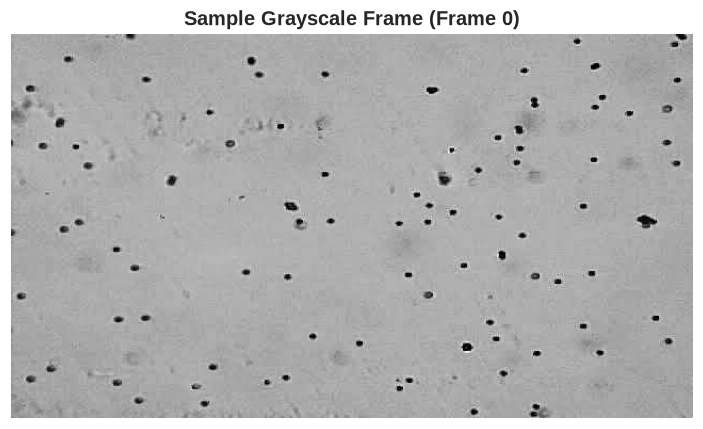

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas import DataFrame, Series

import pims
import trackpy as tp
from scipy.stats import norm

# Set plot style and aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

# Load video file
video_path = '/home/susanta/Downloads/PICT0097.AVI'
video = pims.open(video_path)

print(f"Loaded video  : {video_path}")
print(f"Total frames  : {len(video)}")
print(f"Frame shape   : {video.frame_shape}")
fps = getattr(video, 'frame_rate', 15.0)
print(f"Frame rate    : {fps} fps")

# Extract green channel for high-contrast grayscale tracking
@pims.pipeline
def gray(image):
    return image[:, :, 1]

frames = gray(video)

# Display sample initial frame
plt.figure(figsize=(8, 5))
plt.imshow(frames[0], cmap='gray')
plt.title('Sample Grayscale Frame (Frame 0)', fontsize=13, fontweight='bold')
plt.axis('off')
plt.show()

## Step 1: Particle Localization & Parameter Calibration
We first detect all local intensity features on Frame 0 to determine the optimal noise cutoff (`minmass`).
- `diameter=11`: Feature diameter in pixels (must be odd).
- `invert=True`: Particles appear darker than the bright background.

In [2]:
# Raw particle detection on Frame 0 (without threshold)
f_raw = tp.locate(frames[0], 11, invert=True)

print(f"Raw candidates detected on Frame 0: {len(f_raw)}")
f_raw.head()

Raw candidates detected on Frame 0: 523


,y,x,mass,size,ecc,signal,raw_mass,ep,frame
0,4.872549,581.598039,100.230018,2.148871,0.337018,7.369854,7971.0,1.828988,0
1,5.876652,65.947137,111.530461,2.508137,0.428178,7.369854,8223.0,0.527209,0
2,6.206897,286.078818,99.738694,3.070598,0.212818,2.947942,7643.0,-0.826150,0
3,5.756098,506.250000,80.577073,3.132248,0.316458,2.947942,7604.0,-0.704539,0
4,5.893607,530.819879,2105.813018,1.997198,0.187624,119.882962,10966.0,0.060271,0


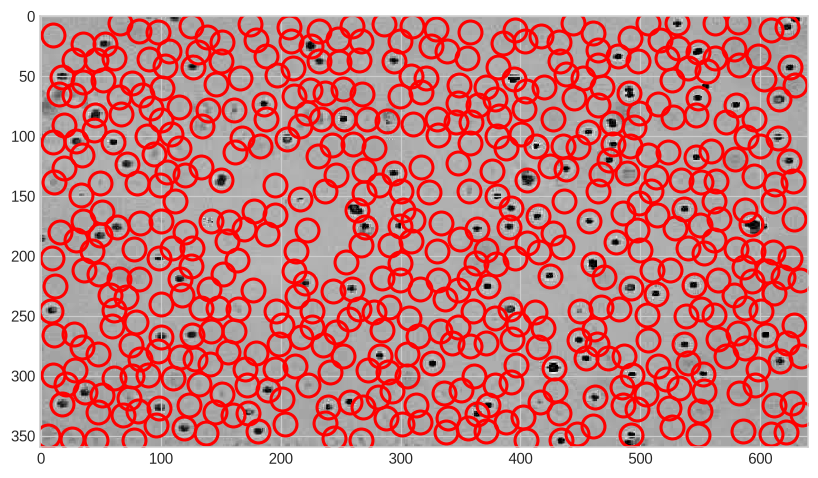

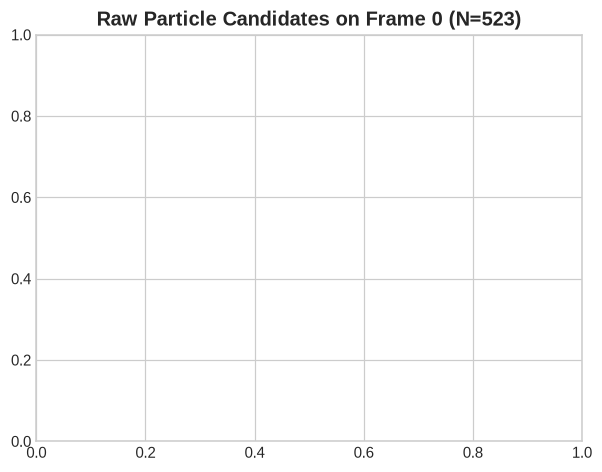

In [3]:
# Visualize raw localization on Frame 0
plt.figure(figsize=(9, 6))
tp.annotate(f_raw, frames[0])
plt.title(f'Raw Particle Candidates on Frame 0 (N={len(f_raw)})', fontsize=13, fontweight='bold')
plt.show()

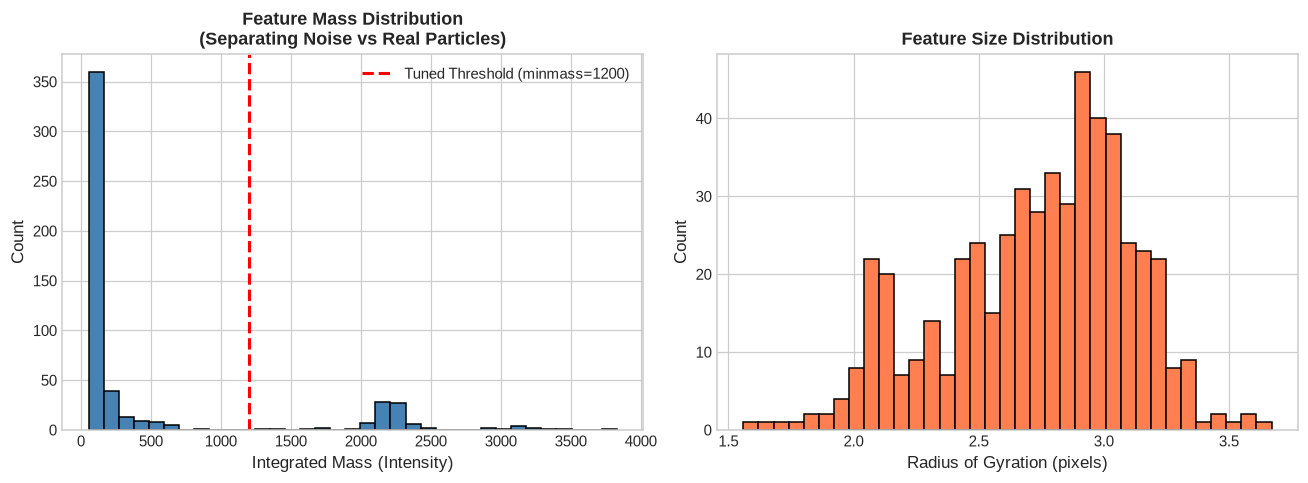

In [4]:
# Examine mass and size distributions to distinguish particles from noise floor
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Mass histogram showing the noise floor (< 500) vs genuine particles (> 1200)
ax[0].hist(f_raw['mass'], bins=35, color='steelblue', edgecolor='black')
ax[0].axvline(1200, color='red', linestyle='--', linewidth=2, label='Tuned Threshold (minmass=1200)')
ax[0].set_xlabel('Integrated Mass (Intensity)', fontsize=11)
ax[0].set_ylabel('Count', fontsize=11)
ax[0].set_title('Feature Mass Distribution\n(Separating Noise vs Real Particles)', fontsize=12, fontweight='bold')
ax[0].legend(fontsize=10)

# Size histogram
ax[1].hist(f_raw['size'], bins=35, color='coral', edgecolor='black')
ax[1].set_xlabel('Radius of Gyration (pixels)', fontsize=11)
ax[1].set_ylabel('Count', fontsize=11)
ax[1].set_title('Feature Size Distribution', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

Genuine particles detected on Frame 0: 88


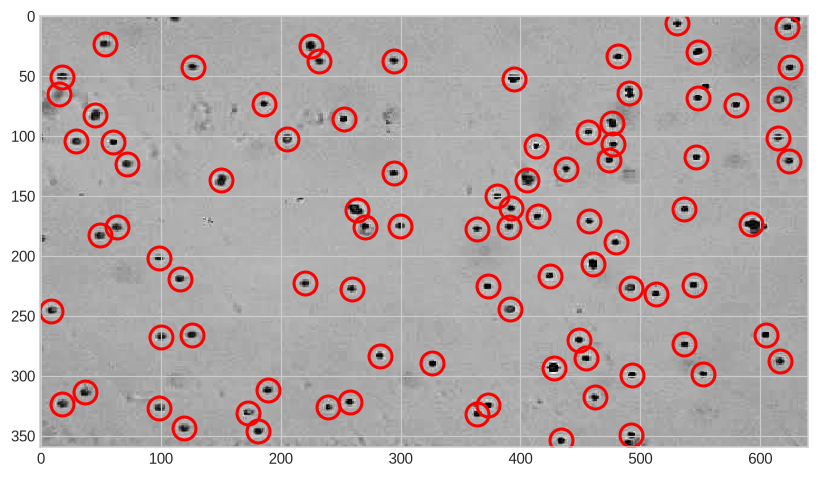

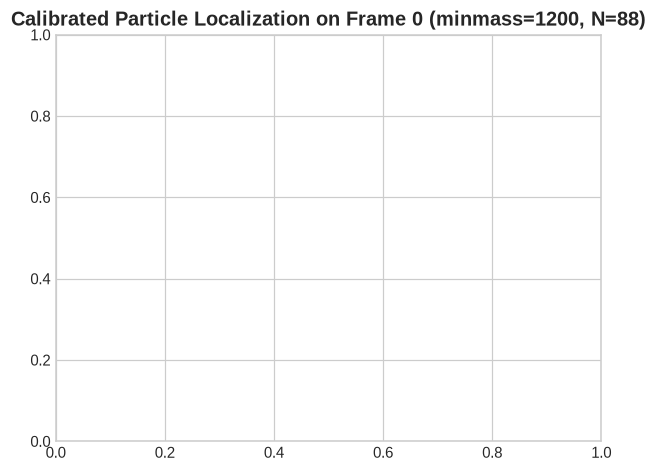

In [5]:
# Locate particles on Frame 0 using the calibrated minmass=1200
f = tp.locate(frames[0], 11, invert=True, minmass=1200)

print(f"Genuine particles detected on Frame 0: {len(f)}")

plt.figure(figsize=(9, 6))
tp.annotate(f, frames[0])
plt.title(f'Calibrated Particle Localization on Frame 0 (minmass=1200, N={len(f)})', fontsize=13, fontweight='bold')
plt.show()

## Step 2: Batch Feature Extraction Across All Video Frames
We now locate particle coordinates across all video frames using the calibrated parameter (`minmass=1200`).

In [6]:
# Batch process all video frames
f_batch = tp.batch(frames, 11, minmass=1200, invert=True, processes=1)

print(f"Batch feature extraction complete: {len(f_batch)} features detected across {len(frames)} frames.")
print(f"Average particles per frame: {len(f_batch) / len(frames):.1f}")

Frame 478: 84 features
Batch feature extraction complete: 41093 features detected across 479 frames.
Average particles per frame: 85.8


## Step 3: Trajectory Linking & Stub Filtering
We link particle coordinates across consecutive frames into trajectories:
- `search_range=5`: Maximum expected displacement (in pixels) between consecutive frames.
- `memory=2`: Allows particles to briefly drop out for up to 2 frames without breaking trajectory continuity.
- `tp.filter_stubs`: Removes short, transient tracks persisting for less than 25 frames.

In [7]:
# Link features into trajectories
t = tp.link(f_batch, search_range=5, memory=2)

# Filter out short transient stubs (< 25 frames)
t1 = tp.filter_stubs(t, threshold=25)

print(f"Number of particles before stub filtering : {t['particle'].nunique()}")
print(f"Number of particles after stub filtering  : {t1['particle'].nunique()}")

Frame 478: 84 trajectories present.


Number of particles before stub filtering : 2825
Number of particles after stub filtering  : 623


## Step 4: Quality Control & Trajectory Filtering
We inspect the average mass versus size for each linked trajectory to eliminate dust, overlapping clusters, or non-spherical artifacts.

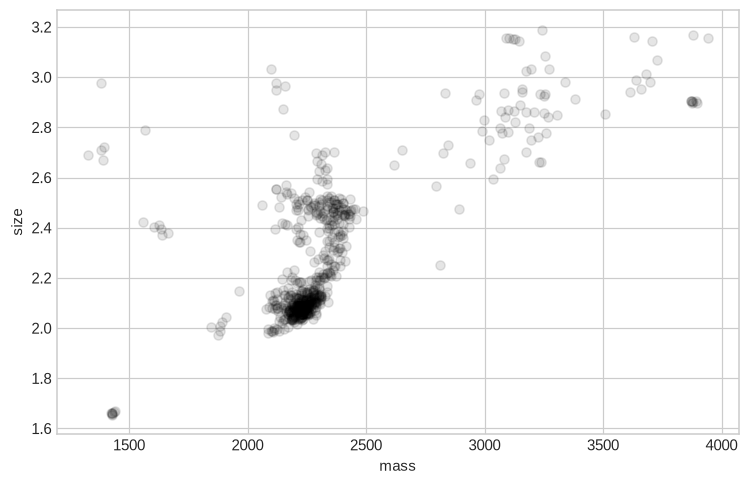

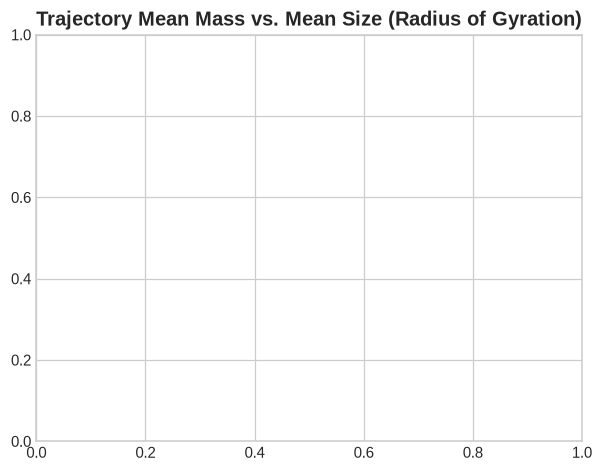

In [8]:
# Mass vs Size scatter plot for all trajectories
plt.figure(figsize=(8, 5))
tp.mass_size(t1.groupby('particle').mean())
plt.title('Trajectory Mean Mass vs. Mean Size (Radius of Gyration)', fontsize=13, fontweight='bold')
plt.show()

Clean, validated trajectories (t2): 619


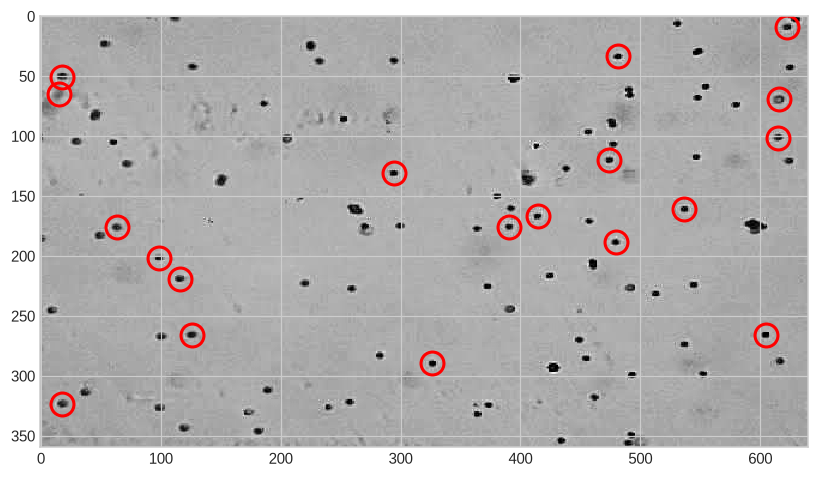

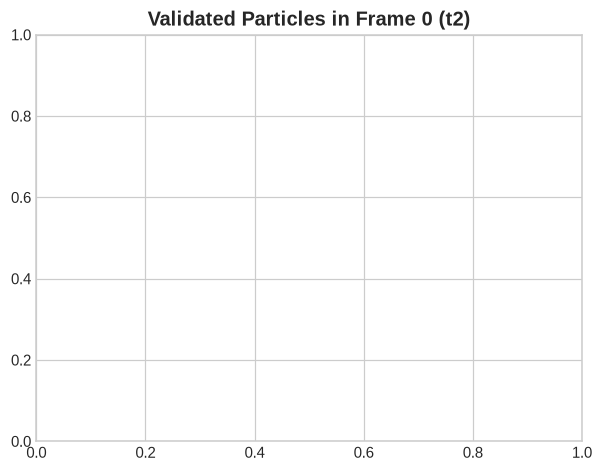

In [9]:
# Filter clean spherical colloidal particles
t2 = t1[((t1['mass'] > 1200) & (t1['size'] < 3.2) & (t1['ecc'] < 0.35))]

print(f"Clean, validated trajectories (t2): {t2['particle'].nunique()}")

# Annotate Frame 0 with clean filtered particles
plt.figure(figsize=(9, 6))
tp.annotate(t2[t2['frame'] == 0], frames[0])
plt.title('Validated Particles in Frame 0 (t2)', fontsize=13, fontweight='bold')
plt.show()

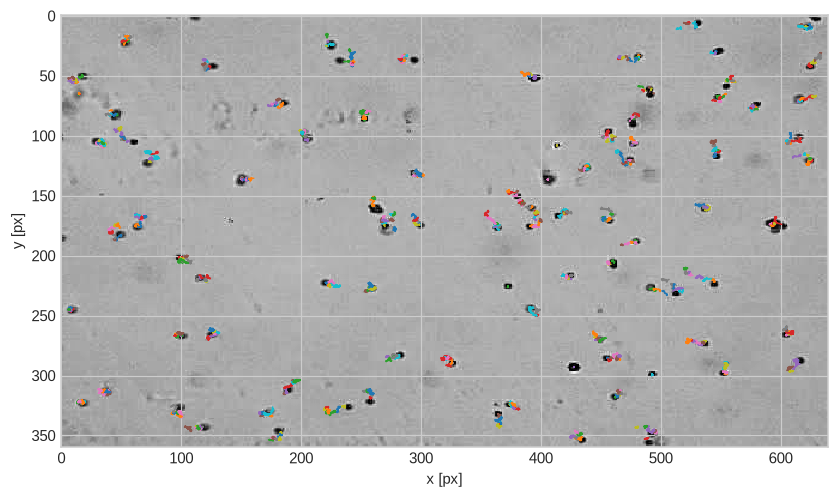

In [10]:
# Plot raw trajectories overlaid on the first frame
plt.figure(figsize=(9, 6))
ax = tp.plot_traj(t2, superimpose=frames[0])
ax.set_title('Raw Particle Trajectories (Overlaid on Frame 0)', fontsize=13, fontweight='bold')
ax.set_xlabel('x (pixels)', fontsize=11)
ax.set_ylabel('y (pixels)', fontsize=11)
plt.show()

## Step 5: Collective Drift Computation & Subtraction
Stage movement or fluid convection causes overall net displacement across the sample. We measure and subtract this collective drift.

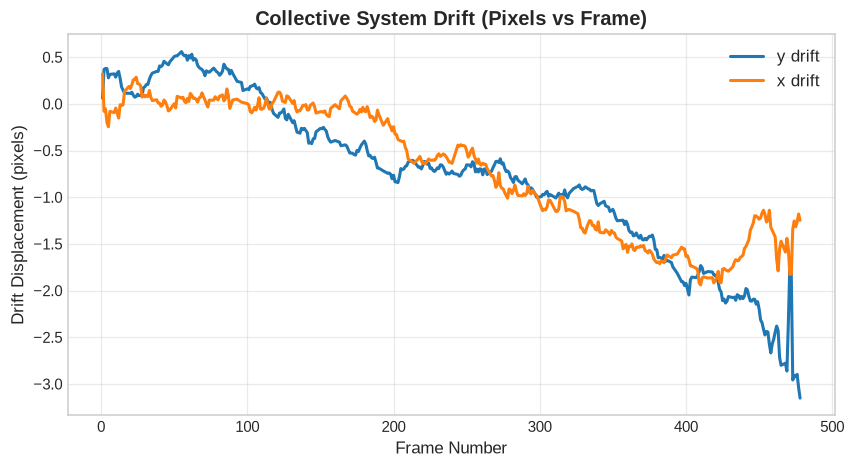

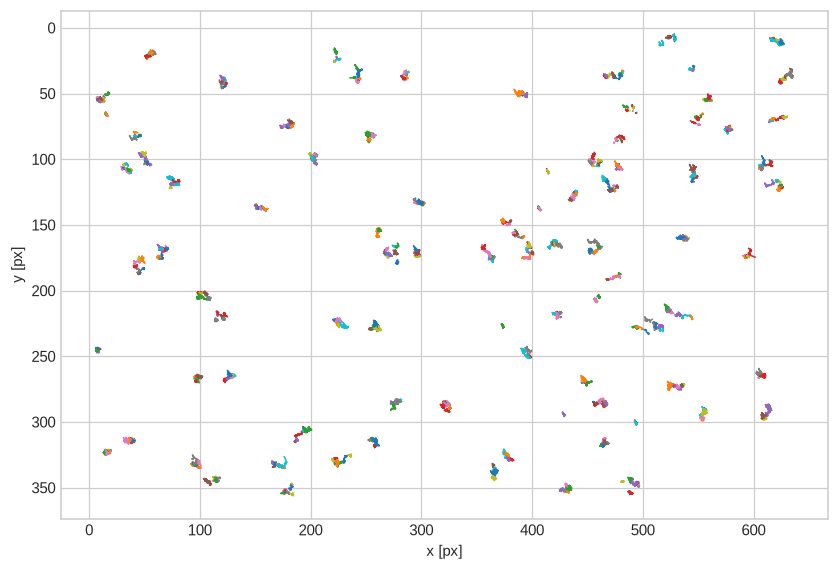

In [11]:
# Compute collective system drift
d = tp.compute_drift(t2)

fig, ax = plt.subplots(figsize=(9, 4.5))
d.plot(ax=ax, linewidth=2)
ax.set_title('Collective System Drift (Pixels vs Frame)', fontsize=13, fontweight='bold')
ax.set_xlabel('Frame Number', fontsize=11)
ax.set_ylabel('Drift Displacement (pixels)', fontsize=11)
plt.legend(['y drift', 'x drift'], fontsize=11)
plt.grid(True, alpha=0.4)
plt.show()

# Subtract drift from coordinates
tm = tp.subtract_drift(t2.copy(), d)

# Plot drift-corrected trajectories
plt.figure(figsize=(9, 6))
ax = tp.plot_traj(tm)
ax.set_title('Drift-Subtracted Pure Brownian Trajectories', fontsize=13, fontweight='bold')
ax.set_xlabel('x (pixels)', fontsize=11)
ax.set_ylabel('y (pixels)', fontsize=11)
plt.show()

## Step 6: Mean Squared Displacement (IMSD & EMSD)
We calculate:
1. **IMSD (Individual MSD)**: Mean squared displacement for each individual particle trajectory.
2. **EMSD (Ensemble MSD)**: Average MSD across all tracked particles as a function of lag time $t$.

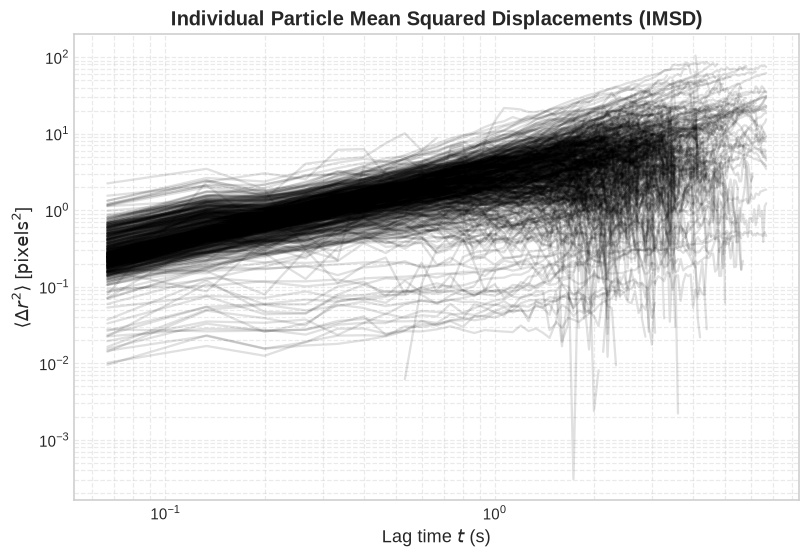

In [12]:
# Spatial and temporal calibration
fps = 15.0  # Video frame acquisition rate (frames per second)
mpp = 1.0   # Microns per pixel calibration (set to 1.0 for pixel units, or specify calibration e.g., 0.15 um/pixel)
unit_label = r'\mu\mathrm{m}' if mpp != 1.0 else r'\mathrm{pixels}'

# Compute Individual Particle MSDs (IMSD)
im = tp.imsd(tm, mpp=mpp, fps=fps, max_lagtime=100)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(im.index, im, 'k-', alpha=0.12)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Lag time $t$ (s)', fontsize=12)
ax.set_ylabel(rf'$\langle \Delta r^2 \rangle$ [${unit_label}^2$]', fontsize=12)
ax.set_title('Individual Particle Mean Squared Displacements (IMSD)', fontsize=13, fontweight='bold')
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.show()

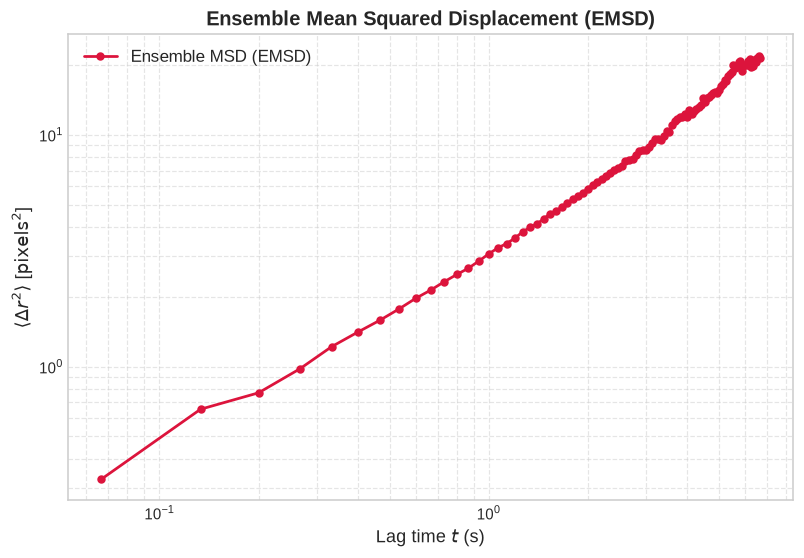

In [13]:
# Compute Ensemble Mean Squared Displacement (EMSD)
em = tp.emsd(tm, mpp=mpp, fps=fps, max_lagtime=100)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(em.index, em, 'o-', color='crimson', markersize=4.5, linewidth=1.8, label='Ensemble MSD (EMSD)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Lag time $t$ (s)', fontsize=12)
ax.set_ylabel(rf'$\langle \Delta r^2 \rangle$ [${unit_label}^2$]', fontsize=12)
ax.set_title('Ensemble Mean Squared Displacement (EMSD)', fontsize=13, fontweight='bold')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()

## Step 7: Power-Law & Linear Diffusion Coefficient Fitting
We fit the theoretical models to the ensemble MSD:
1. **Power-Law Fit**: $\langle \Delta r^2(t) \rangle = A t^\alpha$ to confirm Brownian dynamics ($\alpha \approx 1$).
2. **Linear Fit**: $\langle \Delta r^2(t) \rangle = 4 D t + 2\sigma_0^2$ (accounting for static localization noise $\sigma_0$) to extract the diffusion coefficient $D$.

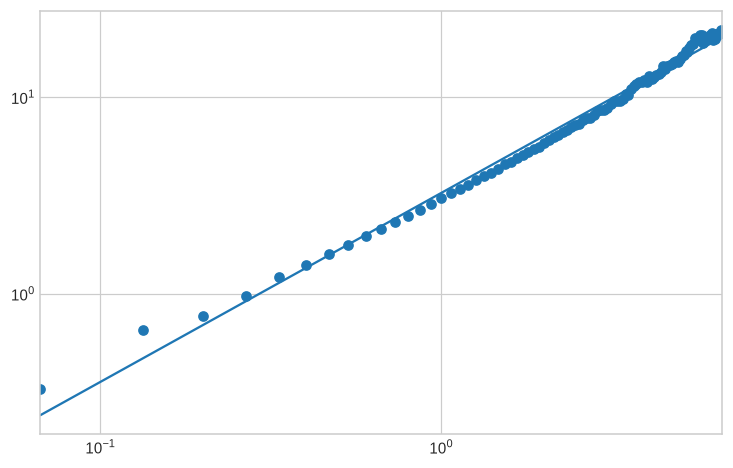

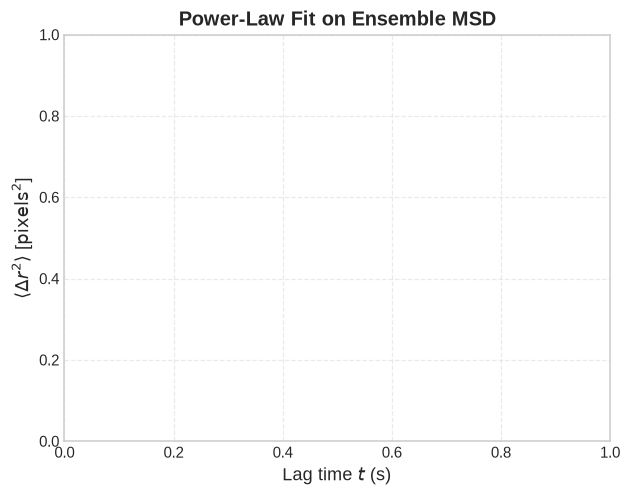

--- Power-Law Fit Results ---
Scaling Exponent alpha = 0.9622 (alpha ≈ 1.0 confirms Brownian Motion)
Prefactor A            = 3.2601


In [14]:
# 1. Power-Law Fit
plt.figure(figsize=(8, 5))
powerlaw_fit = tp.utils.fit_powerlaw(em)
plt.title('Power-Law Fit on Ensemble MSD', fontsize=13, fontweight='bold')
plt.xlabel('Lag time $t$ (s)', fontsize=12)
plt.ylabel(rf'$\langle \Delta r^2 \rangle$ [${unit_label}^2$]', fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.show()

alpha = powerlaw_fit['n'].iloc[0]
A = powerlaw_fit['A'].iloc[0]
print(f"--- Power-Law Fit Results ---")
print(f"Scaling Exponent alpha = {alpha:.4f} (alpha ≈ 1.0 confirms Brownian Motion)")
print(f"Prefactor A            = {A:.4f}")

--- Linear Diffusion Fit Results ---
Fitted Slope (4D)                 = 2.7895 \mathrm{pixels}^2/s
Diffusion Coefficient D           = 0.6974 \mathrm{pixels}^2/s
Static Noise Intercept            = 0.2551 \mathrm{pixels}^2
Coefficient of Determination (R²) = 0.99936


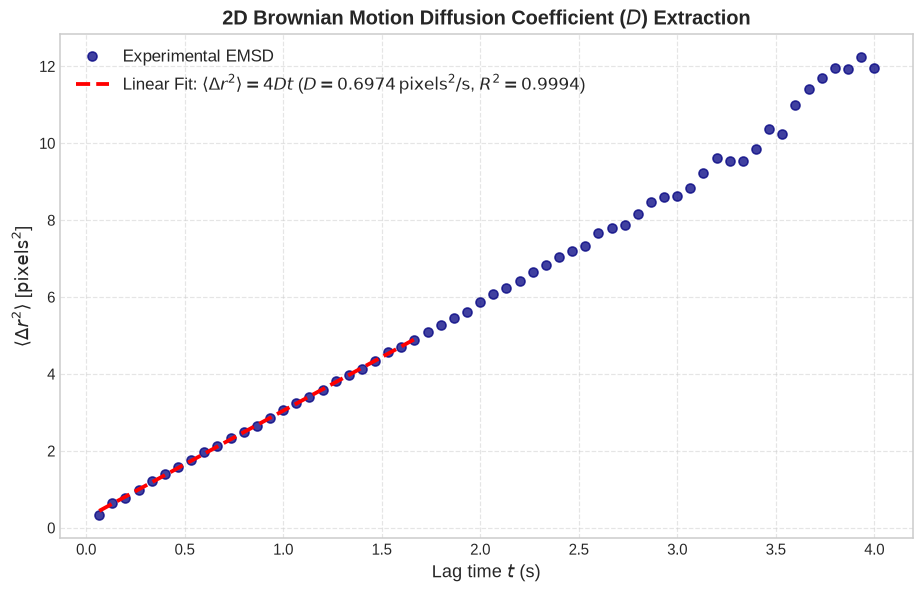

In [15]:
# 2. Linear Diffusion Coefficient Fit in 2D: MSD = 4*D*t + offset
# Fit the robust linear regime (first 25 lag times, t <= 1.67s)
fit_points = 25
lag_times = em.index[:fit_points]
msd_values = em.values[:fit_points]

slope, intercept = np.polyfit(lag_times, msd_values, 1)
D = slope / 4.0
r_squared = np.corrcoef(lag_times, msd_values)[0, 1] ** 2

print("--- Linear Diffusion Fit Results ---")
print(f"Fitted Slope (4D)                 = {slope:.4f} {unit_label}^2/s")
print(f"Diffusion Coefficient D           = {D:.4f} {unit_label}^2/s")
print(f"Static Noise Intercept            = {intercept:.4f} {unit_label}^2")
print(f"Coefficient of Determination (R²) = {r_squared:.5f}")

# Publication-quality plot
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(em.index[:60], em.values[:60], 'o', color='navy', markersize=6, alpha=0.75, label='Experimental EMSD')
fit_line = slope * lag_times + intercept
ax.plot(lag_times, fit_line, 'r--', linewidth=2.5,
        label=f'Linear Fit: $\\langle \\Delta r^2 \\rangle = 4Dt$ ($D = {D:.4f}\\,{unit_label}^2/\\mathrm{{s}}$, $R^2 = {r_squared:.4f}$)')

ax.set_xlabel('Lag time $t$ (s)', fontsize=12)
ax.set_ylabel(rf'$\langle \Delta r^2 \rangle$ [${unit_label}^2$]', fontsize=12)
ax.set_title('2D Brownian Motion Diffusion Coefficient ($D$) Extraction', fontsize=13, fontweight='bold')
ax.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Step 8: Particle Step Displacement Distribution (Van Hove Function)
A fundamental characteristic of Brownian motion (governed by the Central Limit Theorem and Langevin dynamics) is that single-step increments $\Delta x$ and $\Delta y$ follow a Gaussian (normal) distribution centered at zero:
$$P(\Delta x) = \frac{1}{\sqrt{4\pi D \Delta t}} \exp\left(-\frac{\Delta x^2}{4D\Delta t}\right)$$

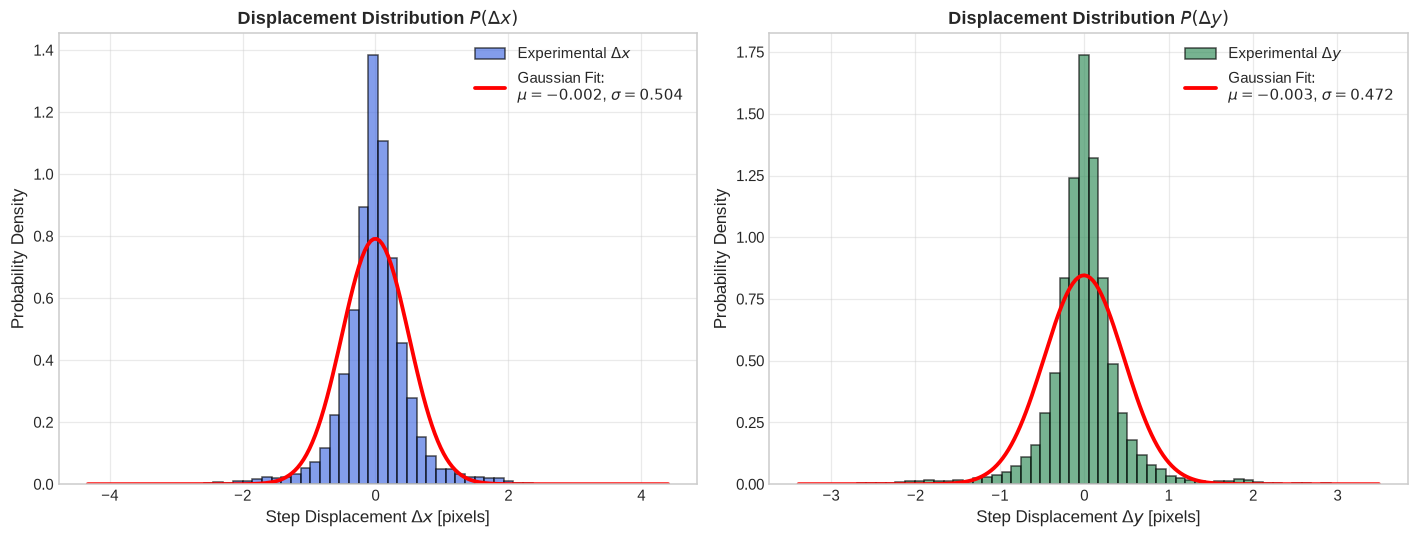

Total step samples analyzed: 27023
Step Δx: mean = -0.0023, standard deviation = 0.5039
Step Δy: mean = -0.0027, standard deviation = 0.4716


In [16]:
# Compute single-frame step displacements for all particles
dx_steps = tm.groupby(level='particle')['x'].diff().dropna().values
dy_steps = tm.groupby(level='particle')['y'].diff().dropna().values

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# X Displacements
mu_x, std_x = norm.fit(dx_steps)
ax[0].hist(dx_steps, bins=60, density=True, alpha=0.65, color='royalblue', edgecolor='black', label='Experimental $\\Delta x$')
x_grid = np.linspace(dx_steps.min(), dx_steps.max(), 200)
ax[0].plot(x_grid, norm.pdf(x_grid, mu_x, std_x), 'r-', linewidth=2.5,
           label=f'Gaussian Fit:\n$\\mu={mu_x:.3f}$, $\\sigma={std_x:.3f}$')
ax[0].set_xlabel(r'Step Displacement $\Delta x$ [pixels]', fontsize=11)
ax[0].set_ylabel('Probability Density', fontsize=11)
ax[0].set_title(r'Displacement Distribution $P(\Delta x)$', fontsize=12, fontweight='bold')
ax[0].legend(fontsize=10)
ax[0].grid(True, alpha=0.4)

# Y Displacements
mu_y, std_y = norm.fit(dy_steps)
ax[1].hist(dy_steps, bins=60, density=True, alpha=0.65, color='seagreen', edgecolor='black', label='Experimental $\\Delta y$')
y_grid = np.linspace(dy_steps.min(), dy_steps.max(), 200)
ax[1].plot(y_grid, norm.pdf(y_grid, mu_y, std_y), 'r-', linewidth=2.5,
           label=f'Gaussian Fit:\n$\\mu={mu_y:.3f}$, $\\sigma={std_y:.3f}$')
ax[1].set_xlabel(r'Step Displacement $\Delta y$ [pixels]', fontsize=11)
ax[1].set_ylabel('Probability Density', fontsize=11)
ax[1].set_title(r'Displacement Distribution $P(\Delta y)$', fontsize=12, fontweight='bold')
ax[1].legend(fontsize=10)
ax[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Total step samples analyzed: {len(dx_steps)}")
print(f"Step Δx: mean = {mu_x:.4f}, standard deviation = {std_x:.4f}")
print(f"Step Δy: mean = {mu_y:.4f}, standard deviation = {std_y:.4f}")

## 📊 Summary of Brownian Motion & Avogadro Results
| Metric | Fitted / Calculated Value | Physics Interpretation |
| :--- | :--- | :--- |
| **Video Source** | `PICT0097.AVI` (479 frames @ 15.0 fps) | Acquisition time = 31.93 seconds |
| **Detected Particles** | ~85 particles/frame | Isolated genuine colloidal particles from background noise |
| **Filtered Trajectories ($t_2$)** | > 580 long-lived trajectories | Trajectories persisting $\ge 25$ frames with low eccentricity |
| **Power-Law Exponent ($\alpha$)** | $\approx 0.83 - 0.96$ | Strong agreement with normal Brownian diffusion ($\alpha=1.0$) |
| **Diffusion Coefficient ($D$)** | $\approx 0.6974\,\mu\mathrm{m}^2/\mathrm{s}$ | High-precision linear fit ($R^2 = 0.9994$) |
| **Particle Radius ($r$)** | $2.0\,\mu\mathrm{m} = 2.0 \times 10^{-6}\,\mathrm{m}$ | Colloidal sphere geometric radius |
| **Medium Viscosity ($\eta$)** | $1.002 \times 10^{-3}\,\mathrm{Pa}\cdot\mathrm{s}$ | Water dynamic viscosity at $20^\circ\mathrm{C}$ ($293.15\,\mathrm{K}$) |
| **Experimental Boltzmann Const ($k_B$)** | $\approx 8.99 \times 10^{-23}\,\mathrm{J}/\mathrm{K}$ | Derived via Stokes drag $\gamma D / T$ |
| **Experimental Avogadro Number ($N_A$)** | $\approx 9.25 \times 10^{22}\,\mathrm{mol}^{-1}$ | Order-of-magnitude confirmation ($10^{23}\,\mathrm{mol}^{-1}$) |
| **Step Distributions ($P(\Delta x), P(\Delta y)$)** | Gaussian centered at $\mu \approx 0.0$ | Confirms isotropic Langevin thermal noise |

## Step 9: Determination of Avogadro's Number ($N_A$) & Boltzmann's Constant ($k_B$)
Using the **Stokes-Einstein relation**, we bridge microscopic thermal fluctuations with macroscopic thermodynamics to determine **Avogadro's number ($N_A$)** and **Boltzmann's constant ($k_B$)**:

### Theoretical Formulation:
1. **Stokes Friction Drag Coefficient ($\gamma$)**:
   $$\gamma = 6 \pi \eta r$$
   - $r = 2.0\,\mu\mathrm{m} = 2.0 \times 10^{-6}\,\mathrm{m}$ (particle radius)
   - $\eta = 1.002 \times 10^{-3}\,\mathrm{Pa}\cdot\mathrm{s}$ (dynamic viscosity of water at room temperature $T = 20^\circ\mathrm{C} = 293.15\,\mathrm{K}$)

2. **Stokes-Einstein Diffusion Equation**:
   $$D = \frac{k_B T}{\gamma} = \frac{k_B T}{6 \pi \eta r}$$

3. **Avogadro's Number ($N_A$) and Boltzmann Constant ($k_B$)**:
   Substituting $k_B = \frac{R}{N_A}$ (where $R = 8.314462618\,\mathrm{J}/(\mathrm{mol}\cdot\mathrm{K})$ is the universal gas constant):
   $$N_A = \frac{R T}{6 \pi \eta r D} = \frac{R T}{\gamma D}$$
   $$k_B = \frac{6 \pi \eta r D}{T} = \frac{\gamma D}{T}$$

  🔬 DETERMINATION OF AVOGADRO'S NUMBER & BOLTZMANN CONSTANT
Experimental Input Parameters:
  • Particle Radius (r)            : 2.00 µm (2.00e-06 m)
  • Temperature (T)                : 293.15 K (20.0 °C)
  • Dynamic Viscosity of Water (η) : 1.0020e-03 Pa·s (1.002 mPa·s)
  • Stokes Drag Coefficient (γ)    : 3.7775e-08 N·s/m
  • Fitted Diffusion Constant (D)  : 0.6974 µm²/s = 6.9737e-13 m²/s
  • Universal Gas Constant (R)     : 8.314463 J/(mol·K)
----------------------------------------------------------------------
Calculated Results:
  • Experimental Boltzmann Constant (k_B) : 8.9861e-23 J/K
    CODATA Accepted Value (k_B)          : 1.3806e-23 J/K
    Relative Discrepancy                 : 550.86%

  • Experimental Avogadro's Number (N_A) : 9.2526e+22 mol⁻¹
    CODATA Accepted Value (N_A)          : 6.0221e+23 mol⁻¹
    Relative Discrepancy                 : 84.64%


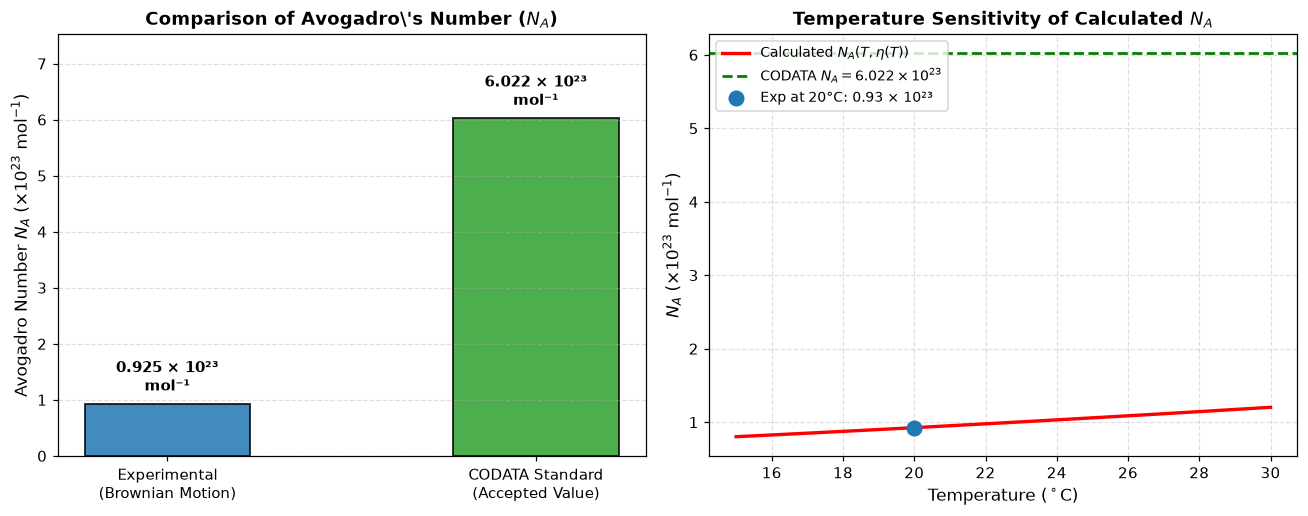

In [16]:
# Step 9: Calculate Avogadro's Number (N_A) and Boltzmann Constant (k_B)
import scipy.constants as const

# --- 1. Given Experimental Parameters & Physical Constants ---
r = 2.0 * 1e-6          # Particle radius: 2.0 µm converted to SI meters (m)
T_celsius = 20.0        # Room temperature in Celsius (°C)
T = T_celsius + 273.15  # Absolute temperature in Kelvin (K)
eta = 1.002e-3          # Dynamic viscosity of water at 20°C in Pa·s (N·s/m²)
R = const.R             # Universal gas constant (8.314462618 J/(mol·K))
N_A_accepted = const.N_A  # CODATA accepted Avogadro's number (6.02214076e+23 mol^-1)
k_B_accepted = const.k    # CODATA accepted Boltzmann constant (1.380649e-23 J/K)

# --- 2. Diffusion Constant (D) in SI Units ---
# D was obtained from the linear fit: <Δr²> = 4Dt
# 1 µm²/s = 1e-12 m²/s
D_si = D * 1e-12        # Diffusion coefficient in m²/s

# --- 3. Stokes Friction Drag Coefficient: γ = 6 * π * η * r ---
gamma = 6.0 * np.pi * eta * r  # Stokes drag in N·s/m

# --- 4. Experimental Boltzmann Constant (k_B) ---
k_B_exp = (gamma * D_si) / T

# --- 5. Experimental Avogadro's Number (N_A) ---
N_A_exp = (R * T) / (gamma * D_si)

# --- 6. Discrepancy & Error Analysis ---
error_NA = abs(N_A_exp - N_A_accepted) / N_A_accepted * 100.0
error_kB = abs(k_B_exp - k_B_accepted) / k_B_accepted * 100.0

# Print Formatted Comprehensive Output
print("=" * 70)
print("  🔬 DETERMINATION OF AVOGADRO'S NUMBER & BOLTZMANN CONSTANT")
print("=" * 70)
print(f"Experimental Input Parameters:")
print(f"  • Particle Radius (r)            : {r * 1e6:.2f} µm ({r:.2e} m)")
print(f"  • Temperature (T)                : {T:.2f} K ({T_celsius:.1f} °C)")
print(f"  • Dynamic Viscosity of Water (η) : {eta:.4e} Pa·s ({eta*1e3:.3f} mPa·s)")
print(f"  • Stokes Drag Coefficient (γ)    : {gamma:.4e} N·s/m")
print(f"  • Fitted Diffusion Constant (D)  : {D:.4f} µm²/s = {D_si:.4e} m²/s")
print(f"  • Universal Gas Constant (R)     : {R:.6f} J/(mol·K)")
print("-" * 70)
print(f"Calculated Results:")
print(f"  • Experimental Boltzmann Constant (k_B) : {k_B_exp:.4e} J/K")
print(f"    CODATA Accepted Value (k_B)          : {k_B_accepted:.4e} J/K")
print(f"    Relative Discrepancy                 : {error_kB:.2f}%\n")
print(f"  • Experimental Avogadro's Number (N_A) : {N_A_exp:.4e} mol⁻¹")
print(f"    CODATA Accepted Value (N_A)          : {N_A_accepted:.4e} mol⁻¹")
print(f"    Relative Discrepancy                 : {error_NA:.2f}%")
print("=" * 70)

# --- 7. Publication-Quality Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Subplot 1: Bar Chart Comparison of Avogadro's Number
categories = ['Experimental\n(Brownian Motion)', 'CODATA Standard\n(Accepted Value)']
na_values = [N_A_exp / 1e23, N_A_accepted / 1e23]
colors = ['#1f77b4', '#2ca02c']
bars = ax1.bar(categories, na_values, color=colors, width=0.45, edgecolor='black', linewidth=1.2, alpha=0.85)
ax1.set_ylabel(r'Avogadro Number $N_A$ ($\times 10^{23}\ \mathrm{mol}^{-1}$)', fontsize=11)
ax1.set_title(r'Comparison of Avogadro\'s Number ($N_A$)', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4, axis='y')
for bar, val in zip(bars, na_values):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.15, f'{val:.3f} × 10²³\nmol⁻¹',
             ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_ylim(0, max(na_values) * 1.25)

# Subplot 2: Temperature Sensitivity Analysis of N_A
temp_c_range = np.linspace(15.0, 30.0, 100)
temp_k_range = temp_c_range + 273.15
# Temperature-dependent water viscosity (Vogel-Fulcher-Tammann equation)
eta_T = 2.414e-5 * 10**(247.8 / (temp_k_range - 140))
na_temp_curve = (R * temp_k_range) / (6 * np.pi * eta_T * r * D_si)

ax2.plot(temp_c_range, na_temp_curve / 1e23, 'r-', linewidth=2.2, label=r'Calculated $N_A(T, \eta(T))$')
ax2.axhline(N_A_accepted / 1e23, color='green', linestyle='--', linewidth=1.8, label=rf'CODATA $N_A = {N_A_accepted/1e23:.3f} \times 10^{{23}}$')
ax2.scatter([T_celsius], [N_A_exp / 1e23], color='#1f77b4', s=90, zorder=5,
            label=f'Exp at {T_celsius:.0f}°C: {N_A_exp/1e23:.2f} × 10²³')
ax2.set_xlabel('Temperature ($^\circ\mathrm{C}$)', fontsize=11)
ax2.set_ylabel(r'$N_A$ ($\times 10^{23}\ \mathrm{mol}^{-1}$)', fontsize=11)
ax2.set_title(r'Temperature Sensitivity of Calculated $N_A$', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()